# Kunci Lab 3: Dummy dan Asumsi Klasik



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita memeriksa dummy dan asumsi model. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah pola antarfitur dan pola residual sebelum membaca hasil uji.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## Latihan 1: heteroskedastisitas (hetero-2)



<!-- kamus_variabel:hetero_2.csv -->

### Kenali data: Pendapatan dan karakteristik pekerja

**Data:** `data/hetero_2.csv`. **Satu baris:** satu orang pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Pendapatan` | Pendapatan selama satu tahun. | Puluhan juta rupiah per tahun, sesuai uraian sumber | Y: target |
| `Pendidikan` | Lama pendidikan yang telah ditempuh. | Tahun | X: penjelas |
| `Pengalaman` | Lama pengalaman kerja. | Tahun | X: penjelas |
| `Usia` | Umur orang yang diamati. | Tahun | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

kerja = pd.read_csv(URL_DATA + "hetero_2.csv")

kerja.head()

,Pendapatan,Pendidikan,Pengalaman,Usia
0,85.67,12,5,28
1,151.02,16,10,35
2,102.43,14,7,31
3,185.33,18,15,40
4,91.11,12,6,29


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
sampel_model_kerja = kerja[["Pendapatan", "Pendidikan", "Pengalaman", "Usia"]].dropna()
X_model_kerja = sampel_model_kerja[["Pendidikan", "Pengalaman", "Usia"]]
y_model_kerja = sampel_model_kerja["Pendapatan"]

In [5]:
model_kerja = LinearRegression()
model_kerja.fit(X_model_kerja, y_model_kerja)

prediksi_model_kerja = pd.Series(
    model_kerja.predict(X_model_kerja), index=y_model_kerja.index
)
residu_model_kerja = y_model_kerja - prediksi_model_kerja


### Lihat hasil model: Produktivitas kerja (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

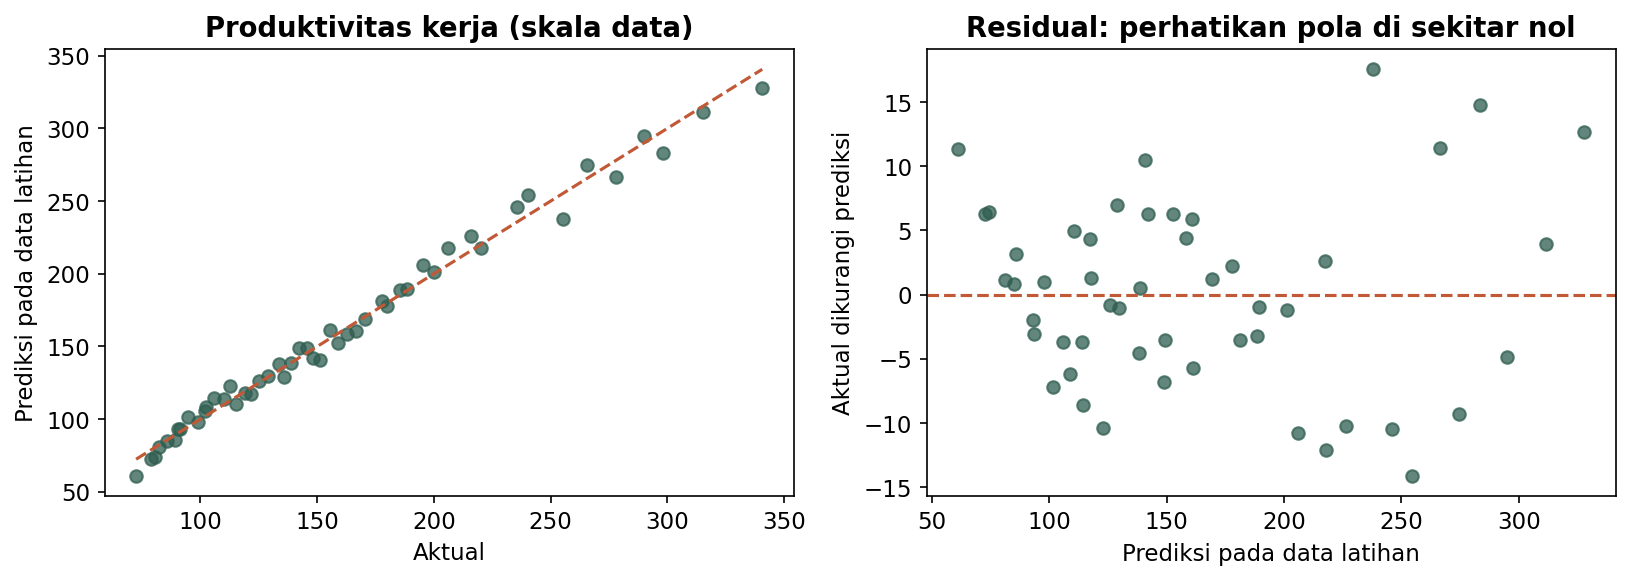

In [6]:
prediksi_visual = model_kerja.predict(X_model_kerja)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_kerja, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_kerja.min(), y_model_kerja.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Produktivitas kerja (skala data)")
axes[1].scatter(prediksi_visual, y_model_kerja - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [7]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_kerja = sm.OLS(
    y_model_kerja,
    sm.add_constant(X_model_kerja, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()

Xk = sm.add_constant(kerja[["Pendidikan", "Pengalaman", "Usia"]])
print("BP p   :", round(het_breuschpagan(residu_model_kerja, Xk)[1], 4))
print("White p:", round(het_white(residu_model_kerja, Xk)[1], 4))

# Pelengkap inferensi: koreksi standard error, dengan X dan y yang sama.
uji_model_robust = sm.OLS(
    y_model_kerja,
    sm.add_constant(X_model_kerja, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit(cov_type="HC3")
banding = pd.DataFrame(
    {
        "p_biasa": uji_model_kerja.pvalues,
        "p_robust": uji_model_robust.pvalues,
    }
)
print(banding.round(4))


BP p   : 0.0025
White p: 0.0638
            p_biasa  p_robust
Intercept    0.7391    0.7164
Pendidikan   0.0089    0.0286
Pengalaman   0.0000    0.0000
Usia         0.6495    0.6084


Kesimpulan: Breusch-Pagan menolak homoskedastis (p = 0,0025), White
tidak menolak pada 5% (p = 0,064). Karena ada bukti heteroskedastis,
laporkan versi robust. Perubahan yang terlihat: p-value pendidikan
naik dari 0,0089 ke 0,0286, tetap signifikan tapi lebih lemah.



## Latihan 2: normalitas (latihan-normalitas-3)



<!-- kamus_variabel:latihan_normalitas_3.csv -->

### Kenali data: Harga dan kondisi rumah

**Data:** `data/latihan_normalitas_3.csv`. **Satu baris:** satu rumah pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Harga` | Harga jual rumah pada data simulasi. | Sumber menyebut juta rupiah sekaligus simulasi dolar; skala ambigu | Y: target |
| `Luas_Bangunan` | Luas bangunan rumah. | Sumber menyebut m² sekaligus simulasi kaki persegi; skala ambigu | X: penjelas |
| `Jumlah_Kamar` | Jumlah kamar tidur. | Kamar | X: penjelas |
| `Usia_Rumah` | Lama sejak rumah dibangun. | Tahun | X: penjelas |

Sumber mencampurkan keterangan satuan untuk harga dan luas. Gunakan angka ini untuk latihan statistik; konfirmasi satuan sebelum memberi interpretasi nominal atau mengonversi luas.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [8]:
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
import seaborn as sns

nrumah = pd.read_csv(URL_DATA + "latihan_normalitas_3.csv")

nrumah.head()

,Harga,Luas_Bangunan,Jumlah_Kamar,Usia_Rumah
0,350,1800,3,15
1,320,1700,3,20
2,380,1900,4,10
3,410,2100,4,5
4,290,1600,3,25


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [9]:
sampel_model_n = nrumah[
    ["Harga", "Luas_Bangunan", "Jumlah_Kamar", "Usia_Rumah"]
].dropna()
X_model_n = sampel_model_n[["Luas_Bangunan", "Jumlah_Kamar", "Usia_Rumah"]]
y_model_n = sampel_model_n["Harga"]

Jarque-Bera = 3.1868, p = 0.2032


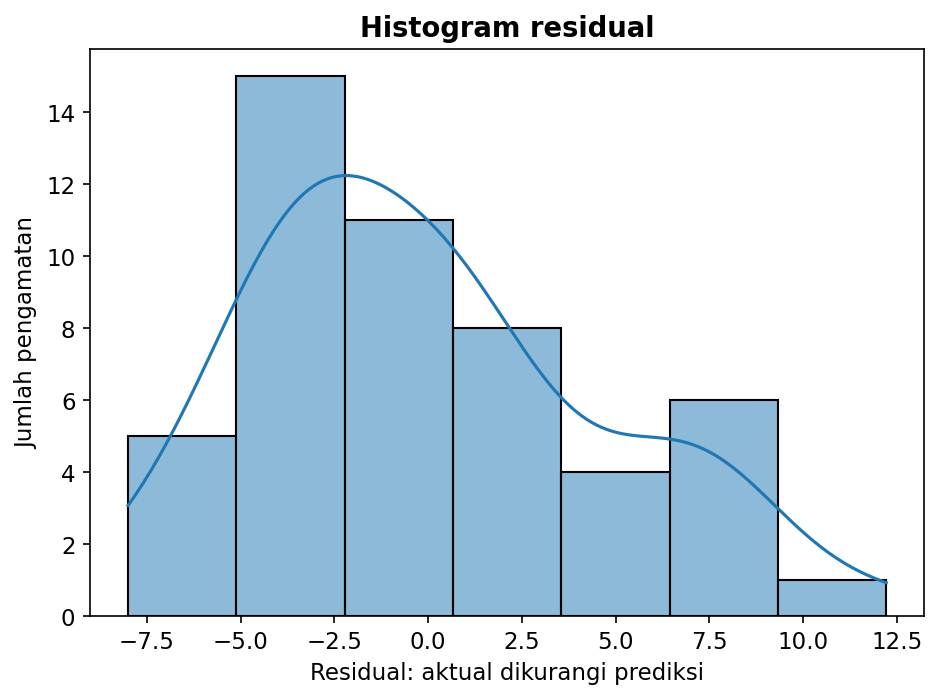

In [10]:
model_n = LinearRegression()
model_n.fit(X_model_n, y_model_n)

prediksi_model_n = pd.Series(model_n.predict(X_model_n), index=y_model_n.index)
residu_model_n = y_model_n - prediksi_model_n

jb, p_jb, skew, kurt = jarque_bera(residu_model_n)
print(f"Jarque-Bera = {jb:.4f}, p = {p_jb:.4f}")

sns.histplot(residu_model_n, kde=True)
plt.title("Histogram residual")
plt.xlabel("Residual: aktual dikurangi prediksi")
plt.ylabel("Jumlah pengamatan")
plt.tight_layout()
plt.show()


**Baca grafik sebelum lanjut:** histogram menunjukkan banyaknya residual pada tiap rentang. Perhatikan kemencengan dan ekor distribusi, lalu cocokkan dengan hasil uji normalitas. Tinggi batang menyatakan jumlah pengamatan, bukan nilai prediksi.

Kesimpulan: p = 0,2032 di atas 0,05, jadi residual tidak menyimpang
jauh dari normal menurut uji ini; gagal menolak bukan membuktikan normalitas.



## Latihan 3: kasus tanpa pelanggaran (hetero-1)



<!-- kamus_variabel:hetero_1.csv -->

### Kenali data: Iklan, tenaga penjualan, dan diskon

**Data:** `data/hetero_1.csv`. **Satu baris:** satu pengamatan penjualan perusahaan dalam contoh.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Penjualan` | Banyaknya produk terjual. | Ribuan unit | Y: target |
| `Iklan` | Pengeluaran untuk iklan. | Juta rupiah | X: penjelas |
| `Salesperson` | Jumlah tenaga penjualan yang bekerja. | Orang | X: penjelas |
| `Diskon` | Rata-rata potongan harga yang diberikan. | Persen; 5,2 berarti 5,2% | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [11]:
jual = pd.read_csv(URL_DATA + "hetero_1.csv")

jual.head()

,Penjualan,Iklan,Salesperson,Diskon
0,231.83,10.5,8,5.2
1,272.94,12.2,9,6.1
2,251.35,11.8,7,5.5
3,333.31,15.1,10,7.3
4,311.66,14.5,11,6.8


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [12]:
sampel_model_jual = jual[["Penjualan", "Iklan", "Salesperson", "Diskon"]].dropna()
X_model_jual = sampel_model_jual[["Iklan", "Salesperson", "Diskon"]]
y_model_jual = sampel_model_jual["Penjualan"]

In [13]:
model_jual = LinearRegression()
model_jual.fit(X_model_jual, y_model_jual)

prediksi_model_jual = pd.Series(
    model_jual.predict(X_model_jual), index=y_model_jual.index
)
residu_model_jual = y_model_jual - prediksi_model_jual
Xj = sm.add_constant(jual[["Iklan", "Salesperson", "Diskon"]])
print("BP p   :", round(het_breuschpagan(residu_model_jual, Xj)[1], 4))
print("White p:", round(het_white(residu_model_jual, Xj)[1], 4))


BP p   : 0.9969
White p: 0.5424


### Lihat hasil model: Penjualan (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

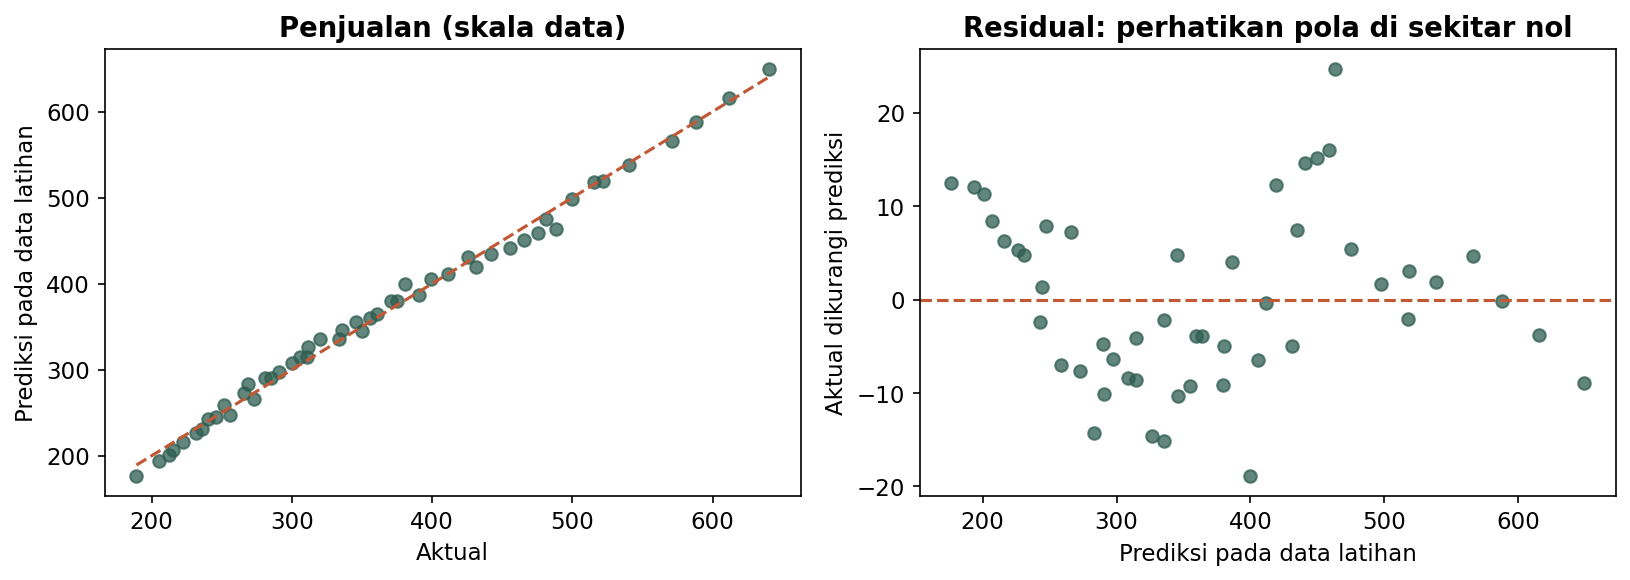

In [14]:
prediksi_visual = model_jual.predict(X_model_jual)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_jual, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_jual.min(), y_model_jual.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Penjualan (skala data)")
axes[1].scatter(prediksi_visual, y_model_jual - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

Kesimpulan: kedua uji tidak menolak homoskedastis (p = 0,997 dan 0,542).
Dugaan "variabilitas penjualan membesar saat iklan tinggi" tidak
didukung data ini. Yang benar: laporkan apa adanya, jangan paksakan
narasi. Ini juga contoh bahwa hipotesis bisa ditolak data.
